# Fashion Apparel Image Synthesizer using DCGAN

**Deep Learning project submission notebook**

This notebook documents and runs the CPU-based DCGAN project implemented in `src/train.py` and `src/generate.py`.

**Dataset:** Fashion-MNIST  
**Framework:** TensorFlow / Keras  
**Training mode:** CPU  
**Outputs:** generated image grids, loss curves, saved Generator and Discriminator models

> Run this notebook from the project root folder (`Fashion-Apparel-DCGAN`). The training cell can take time on a CPU. Set `RUN_TRAINING = False` if you only want to inspect artifacts from a run that has already completed.


## 1. Imports and project paths

In [1]:
from pathlib import Path
import os
import subprocess
import sys
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

PROJECT_ROOT = Path.cwd()
TRAIN_SCRIPT = PROJECT_ROOT / "src" / "train.py"
GENERATE_SCRIPT = PROJECT_ROOT / "src" / "generate.py"
GENERATED_DIR = PROJECT_ROOT / "generated_images"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"

for folder in [GENERATED_DIR, RESULTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Training script exists:", TRAIN_SCRIPT.exists())
print("Generation script exists:", GENERATE_SCRIPT.exists())



Project root: c:\Users\aryan\Fashion-Apparel-DCGAN
Training script exists: True
Generation script exists: True


## 2. Verify TensorFlow and CPU device

In [2]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available physical devices:", tf.config.list_physical_devices())
print("Training will use CPU if no supported GPU is available.")


TensorFlow version: 2.22.0-rc0
Available physical devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Training will use CPU if no supported GPU is available.


## 3. Dataset overview

Training images: 60000
Test images: 10000
Image shape: (28, 28) pixels
Number of classes: 10


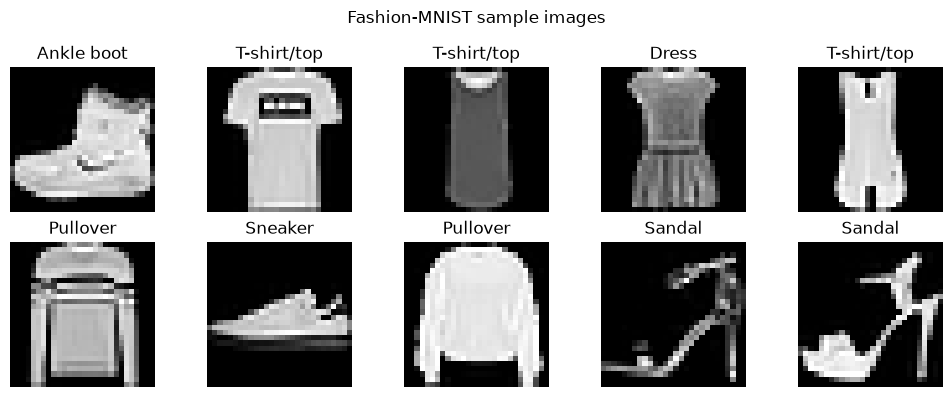

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print(f"Training images: {x_train.shape[0]}")
print(f"Test images: {x_test.shape[0]}")
print(f"Image shape: {x_train.shape[1:]} pixels")
print(f"Number of classes: {len(class_names)}")

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(class_names[y_train[i]])
    ax.axis("off")
plt.suptitle("Fashion-MNIST sample images")
plt.tight_layout()
plt.show()


## 4. Train the DCGAN (optional)

The training code is maintained in `src/train.py`. Set `RUN_TRAINING = True` to run a fresh training session from this notebook. This can take a while on a CPU, especially for 30 epochs.

If you already trained the model in VS Code and want to document the existing outputs first, leave this set to `False`.


In [4]:
RUN_TRAINING = False  # Change to True for a fresh training run

if RUN_TRAINING:
    if not TRAIN_SCRIPT.exists():
        raise FileNotFoundError(f"Could not find training script: {TRAIN_SCRIPT}")
    result = subprocess.run(
        [sys.executable, str(TRAIN_SCRIPT)],
        cwd=str(PROJECT_ROOT),
        check=False
    )
    print("Training process exit code:", result.returncode)
    if result.returncode != 0:
        raise RuntimeError("Training script failed. Check the error output above.")
else:
    print("Skipped training. Using existing saved artifacts, if available.")


Skipped training. Using existing saved artifacts, if available.


## 5. Visualize epoch-wise generated samples

Epoch sample grids found: 30
Displaying: c:\Users\aryan\Fashion-Apparel-DCGAN\generated_images\epoch_030.png


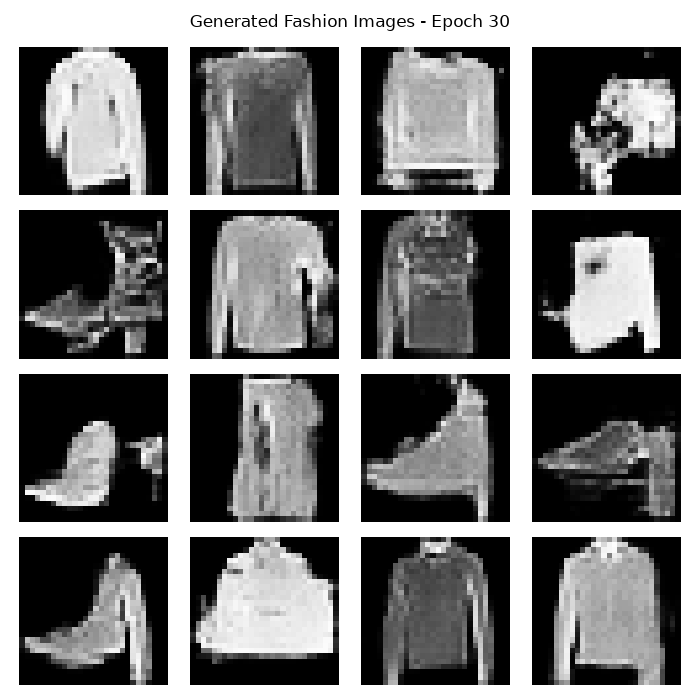

In [5]:
sample_files = sorted(GENERATED_DIR.glob("epoch_*.png"))

print("Epoch sample grids found:", len(sample_files))
if sample_files:
    latest_sample = sample_files[-1]
    print("Displaying:", latest_sample)
    display(Image.open(latest_sample))
else:
    print("No epoch sample grids found. Run training first.")


## 6. Display the training loss curve

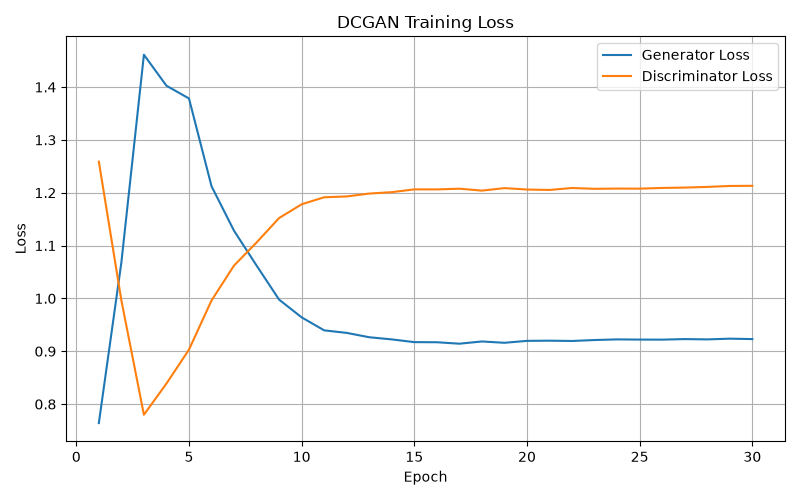

Loss curve file: c:\Users\aryan\Fashion-Apparel-DCGAN\results\loss_curves.png


In [6]:
loss_path = RESULTS_DIR / "loss_curves.png"

if loss_path.exists():
    display(Image.open(loss_path))
    print("Loss curve file:", loss_path)
else:
    print("Loss curve not found. Run src/train.py first.")


## 7. Generate new apparel images

This cell runs `src/generate.py`, which loads the saved Generator and creates a new 4×4 grid at `results/new_fashion_images.png`.


In [7]:
RUN_GENERATION = True

if RUN_GENERATION:
    if not GENERATE_SCRIPT.exists():
        raise FileNotFoundError(f"Could not find generation script: {GENERATE_SCRIPT}")
    generator_result = subprocess.run(
        [sys.executable, str(GENERATE_SCRIPT)],
        cwd=str(PROJECT_ROOT),
        check=False
    )
    print("Generation process exit code:", generator_result.returncode)
    if generator_result.returncode != 0:
        raise RuntimeError("Image generation failed. Check the error output above.")


Generation process exit code: 0


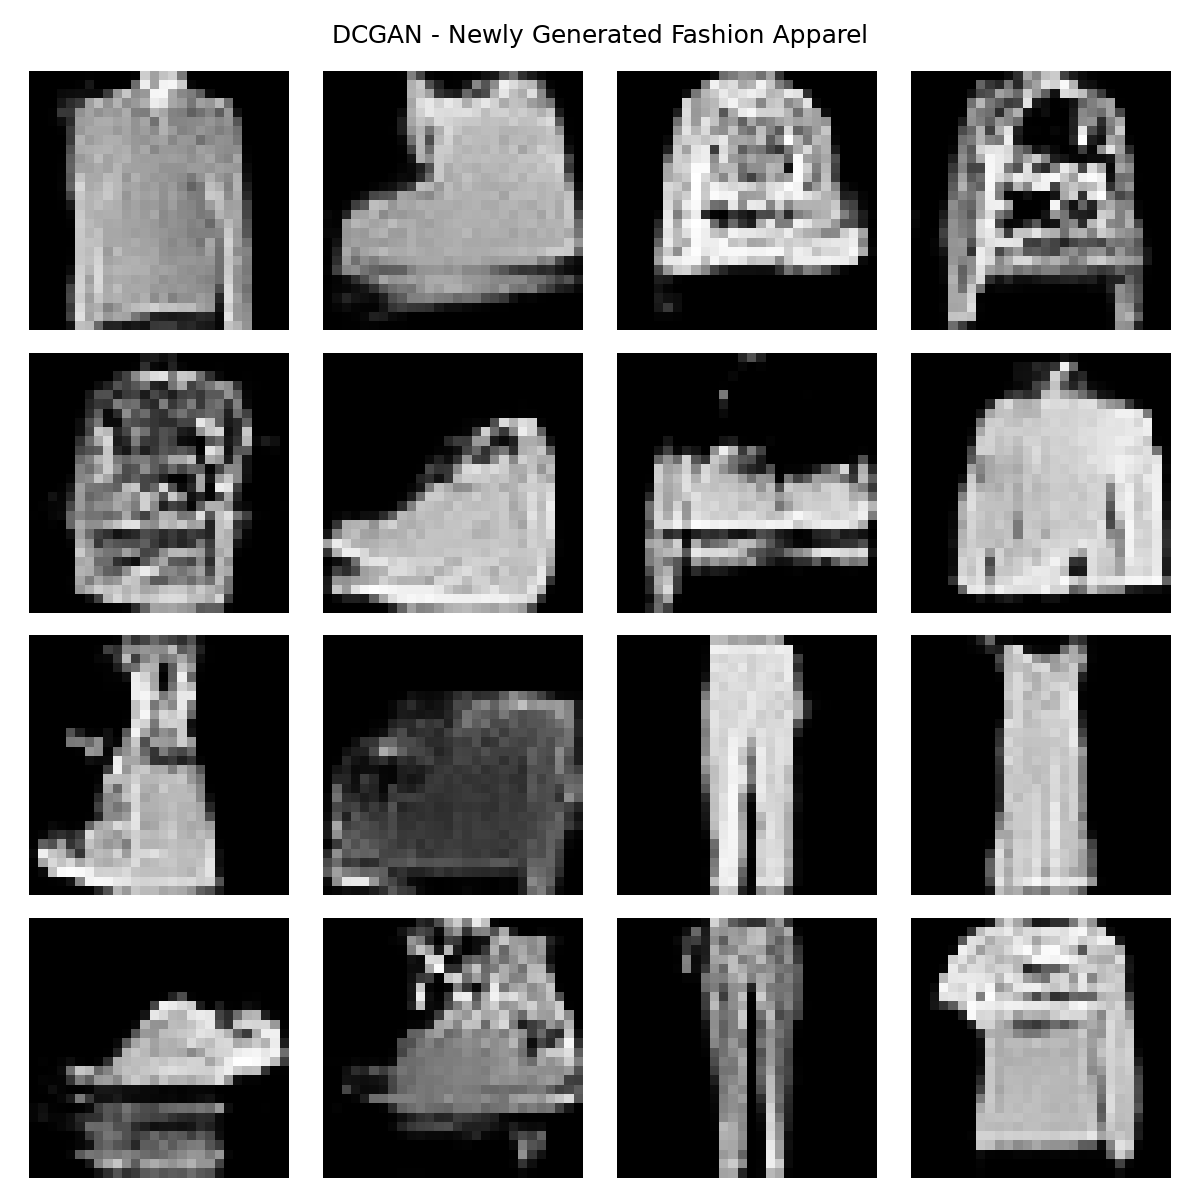

Generated image grid saved to: c:\Users\aryan\Fashion-Apparel-DCGAN\results\new_fashion_images.png


In [8]:
new_images_path = RESULTS_DIR / "new_fashion_images.png"

if new_images_path.exists():
    display(Image.open(new_images_path))
    print("Generated image grid saved to:", new_images_path)
else:
    print("Generated image grid not found. Confirm the generation script completed.")


## 8. Verify submission artifacts

In [9]:
expected_artifacts = [
    TRAIN_SCRIPT,
    GENERATE_SCRIPT,
    PROJECT_ROOT / "requirements.txt",
    PROJECT_ROOT / "README.md",
    MODELS_DIR / "generator.keras",
    MODELS_DIR / "discriminator.keras",
    RESULTS_DIR / "loss_curves.png",
    RESULTS_DIR / "new_fashion_images.png",
]

for path in expected_artifacts:
    print(("FOUND  " if path.exists() else "MISSING"), path.relative_to(PROJECT_ROOT))


FOUND   src\train.py
FOUND   src\generate.py
FOUND   requirements.txt
FOUND   README.md
FOUND   models\generator.keras
FOUND   models\discriminator.keras
FOUND   results\loss_curves.png
FOUND   results\new_fashion_images.png


## 9. Results and observations

Fill in this section after the final run using the values printed in your terminal and the actual generated images.

- **Dataset:** Fashion-MNIST (28×28 grayscale images)
- **Model:** DCGAN with Generator and Discriminator
- **Compute:** CPU
- **Training epochs completed:** Record the actual number here
- **Observed output quality:** Describe visible patterns and limitations without claiming that every output is realistic
- **Loss behaviour:** GAN losses can fluctuate; interpret them alongside generated samples

**Current limitations:** low-resolution grayscale outputs, possible blurry or malformed apparel shapes, and relatively slow CPU training. A longer run and careful hyperparameter tuning may improve quality.


## 10. Reproducibility notes

1. Activate the project's `.venv` environment.
2. Install dependencies using `python -m pip install -r requirements.txt`.
3. Open this notebook from the project root.
4. Select the Python interpreter from `.venv`.
5. Run cells from top to bottom. For a fresh run, set `RUN_TRAINING = True`.
6. Save the notebook after all cells have executed and outputs are visible.
7. Verify the generated image and loss-curve files before sharing the notebook.

**Important:** A notebook is considered fully executed when the relevant code cells have been run and their outputs are saved in the `.ipynb` file. Do not submit it with empty output cells if the instructions require a fully executed notebook.
